<a href="https://colab.research.google.com/github/edirnolove/FDG-2026/blob/main/semana06/EDIR_GONZANO_LAB_D7_FGD_2026II_ESTUDIANTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LABORATORIO DIRIGIDO N.° 07

**Semana 7 · Aprendizaje no supervisado: clustering con K-Means**  
Segmentación del conjunto Auto MPG con K-Means, método del codo y silueta, y registro de los segmentos en SQLite, para el caso AutoFlota Andina  
Curso: Fundamentos de Gestión de Datos · Periodo: 2026-II · Docente: Pilar Rocío Sayán Mejía  
Datos: `auto-mpg.data` (UCI Machine Learning Repository, dataset Auto MPG)

## Actividad 1 — Revisión de conceptos

Complete la tabla con definiciones elaboradas con sus propias palabras. No se admite la reproducción literal de fuentes externas ni de sistemas generativos.

| Concepto | Definición con sus propias palabras | Pregunta de apoyo |
|---|---|---|
| Aprendizaje supervisado y no supervisado |  | En la semana 6 se predijo el rendimiento. ¿Qué cambia hoy si no hay una variable objetivo? Den un ejemplo de cada tipo. |
| Segmentación (clustering) |  | ¿Qué significa que los autos de un grupo se parezcan entre sí y se diferencien de los otros? ¿Para qué sirve esto en AutoFlota Andina? |
| Escalado con StandardScaler |  | El peso va de 1 600 a 5 100 y la aceleración de 8 a 25. ¿Por qué hay que escalar antes de calcular distancias? |
| K-Means: centroides e iteraciones |  | ¿Qué hace K-Means en cada iteración y cuándo se detiene? |
| Inercia y método del codo |  | ¿Por qué la inercia siempre baja al aumentar k y cómo se usa entonces el codo para elegir k? |
| Silueta y perfil del segmento |  | ¿Qué indica una silueta cercana a 1 y cómo se convierte un grupo numérico en un segmento con nombre de negocio? |
| CRISP-DM |  | ¿Cuáles son las seis fases y en cuál de ellas se ubica el ajuste de K-Means de hoy? |


## Actividad 2 — Desarrollo práctico y ejecución

### Caso de estudio: AutoFlota Andina (continuación)

AutoFlota Andina ya limpió sus datos y estimó el rendimiento de sus autos. Ahora necesita ordenar la oferta de vehículos en tipos, para decidir la compra por tipo de uso. Como nadie ha etiquetado los autos en grupos, el equipo de datos aplica un método no supervisado: K-Means agrupa los autos que se parecen en peso, potencia, aceleración y rendimiento.

> **Naturaleza de los datos.** Conjunto real e histórico del repositorio UCI Machine Learning Repository (Auto MPG, Quinlan, 1993) con 398 vehículos de los años de modelo 1970 a 1982, el mismo de las semanas 5 y 6. AutoFlota Andina es un caso ilustrativo. Los datos sirven para practicar segmentación, no para elegir vehículos actuales.

Variables: se usan peso (libras), potencia (hp), aceleracion (segundos de 0 a 60 mph) y rendimiento_mpg. No hay variable objetivo: el modelo descubre los grupos. Los nombres están en español, como en las semanas anteriores.

La tabla autos_limpio de SQLite guarda el resultado de la limpieza de la semana 6 y, al final del laboratorio, recibe una columna nueva con el segmento de cada auto.

**Recorrido CRISP-DM.** Cada parte del laboratorio corresponde a una fase del proceso CRISP-DM; las fases son iterativas.

| Fase CRISP-DM | Dónde está en este laboratorio |
|---|---|
| 1. Comprensión del negocio | Caso de estudio: ordenar la oferta en tipos de auto para decidir la compra. |
| 2. Comprensión de los datos | Celdas 1 y 2: tabla autos_limpio y descripción de las variables. |
| 3. Preparación de los datos | Celdas 2 y 3: elección de variables y escalado con StandardScaler. |
| 4. Modelado | Celdas 4 y 7: ajuste de K-Means. |
| 5. Evaluación | Celdas 5, 6, 8 y 9: codo, silueta, perfiles y gráfico. |
| 6. Despliegue | Celdas 10 y 11: registro en SQLite y asignación de los candidatos. |
| Iteración | Retos 1 a 3: se vuelve a la preparación y al modelado para comprobar las decisiones. |

### Preparación del entorno

Abra el notebook en Google Colab y ejecute la celda 1: importa las librerías, descarga el archivo desde UCI, repite la limpieza de la semana 6 (potencia imputada con la mediana, origen y año corregidos), la guarda en autos_limpio y la lee con pd.read_sql_query().

**Celda 1 de 14**

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Auto MPG de UCI. Se repite la limpieza de la semana 6 para partir de la tabla limpia
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
crudo["potencia"] = crudo["potencia"].fillna(crudo["potencia"].median())
crudo["origen"] = crudo["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
crudo["anio"] = 1900 + crudo["anio_modelo"]

conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_limpio", conexion, index=False)

autos = pd.read_sql_query("SELECT * FROM autos_limpio;", conexion)
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 11)


#### A. Preparar las variables y ajustar K-Means

### Ejercicio 1 — Elegir y escalar las variables

**Fase CRISP-DM.** Comprensión y preparación de los datos.

Para segmentar se eligen variables numéricas que describan los casos, sin faltantes y sin variable objetivo. K-Means mide distancias, así que las variables deben tener escalas comparables: StandardScaler resta el promedio y divide por la desviación estándar de cada una.

**Se solicita.** Ejecute las celdas 2 y 3.

**Celda 2 de 14**

In [3]:
variables = ["peso", "potencia", "aceleracion", "rendimiento_mpg"]
display(autos[variables].describe().round(2))
print("Faltantes en las variables elegidas:", autos[variables].isna().sum().sum())

,peso,potencia,aceleracion,rendimiento_mpg
count,398.00,398.00,398.00,398.00
mean,2970.42,104.30,15.57,23.51
std,846.84,38.22,2.76,7.82
min,1613.00,46.00,8.00,9.00
25%,2223.75,76.00,13.82,17.50
50%,2803.50,93.50,15.50,23.00
75%,3608.00,125.00,17.18,29.00
max,5140.00,230.00,24.80,46.60


Faltantes en las variables elegidas: 0


**Celda 3 de 14**

In [4]:
escalador = StandardScaler()
Z = pd.DataFrame(escalador.fit_transform(autos[variables]), columns=variables)
display(Z.describe().round(2).loc[["mean", "std"]])

,peso,potencia,aceleracion,rendimiento_mpg
mean,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


**Pregunta 1.** ¿Por qué se eligieron estas cuatro variables y por qué no entran codigo_origen ni nombre_auto? ¿Hay una variable objetivo?

**Respuesta:** Se eligieron peso, potencia, aceleración y rendimiento porque son numéricas, describen al auto y no tienen faltantes (0). codigo_origen es una categoría guardada como número y nombre_auto es texto, así que no sirven para calcular distancias. No hay variable objetivo: el modelo descubre los grupos.

**Pregunta 2.** ¿Qué diferencia de escala muestra la celda 2 y qué resultado confirma la celda 3 después de escalar? ¿Qué pasaría sin escalar?

**Respuesta:** El peso va de 1613 a 5140 y la aceleración de 8 a 24.8, escalas muy distintas. Después de escalar, todas las variables tienen promedio 0 y desviación 1. Sin escalar, el peso dominaría las distancias y las demás variables casi no influirían.

### Ejercicio 2 — Primer ajuste de K-Means

**Fase CRISP-DM.** Modelado.

K-Means elige k centroides, asigna cada auto al centroide más cercano, recalcula cada centroide como el promedio de su grupo y repite hasta que las asignaciones no cambian. n_init = 10 prueba diez inicializaciones y conserva la mejor; random_state = 42 fija el sorteo.

**Se solicita.** Ejecute la celda 4.

**Celda 4 de 14**

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
km.fit(Z)

print("Iteraciones hasta converger:", km.n_iter_)
print("Inercia:", round(km.inertia_, 1))
print("Autos por grupo:", np.bincount(km.labels_))
display(pd.DataFrame(km.cluster_centers_, columns=variables).round(2))

Iteraciones hasta converger: 8
Inercia: 500.3
Autos por grupo: [ 97 156 145]


,peso,potencia,aceleracion,rendimiento_mpg
0,1.39,1.51,-1.06,-1.15
1,0.00,-0.17,0.25,-0.28
2,-0.93,-0.83,0.45,1.07


**Pregunta 3.** ¿En cuántas iteraciones convergió, cuánto vale la inercia y cuántos autos hay por grupo? ¿Qué representa cada fila de cluster_centers_?

**Respuesta:** Convergió en 8 iteraciones, la inercia vale 500.3 y los grupos tienen 97, 156 y 145 autos. Cada fila de cluster_centers_ es el centroide de un grupo: el valor promedio (escalado) de cada variable para ese grupo.

#### B. Elegir k e interpretar los segmentos

### Ejercicio 3 — Elegir el número de grupos

**Fase CRISP-DM.** Evaluación.

La inercia es la suma de las distancias al cuadrado de cada auto a su centroide: siempre baja al aumentar k, por eso se busca el codo, donde la mejora deja de ser grande. La silueta mide, entre −1 y 1, qué tan bien separado está cada auto de los otros grupos.

**Se solicita.** Ejecute las celdas 5 y 6.

**Celda 5 de 14**

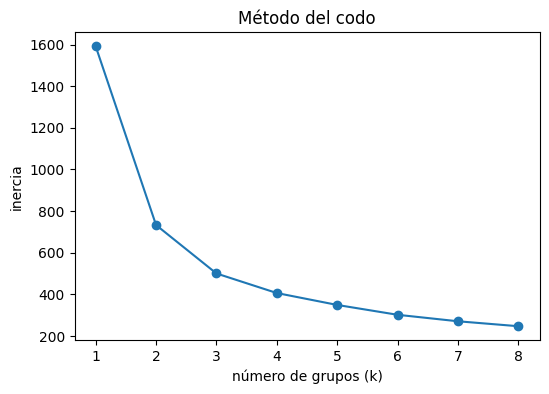

,k,inercia
0,1,1592.0
1,2,733.0
2,3,500.3
3,4,406.3
4,5,349.1
5,6,301.8
6,7,270.6
7,8,246.9


In [6]:
inercias = []
for k in range(1, 9):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercias.append(modelo_k.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 9), inercias, marker="o")
plt.xlabel("número de grupos (k)")
plt.ylabel("inercia")
plt.title("Método del codo")
plt.show()
display(pd.DataFrame({"k": range(1, 9), "inercia": np.round(inercias, 1)}))

**Celda 6 de 14**

In [7]:
siluetas = {}
for k in range(2, 9):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    siluetas[k] = round(silhouette_score(Z, etiquetas), 3)
display(pd.Series(siluetas, name="silueta"))

,silueta
2,0.500
3,0.375
4,0.348
5,0.335
6,0.299
7,0.293
8,0.290


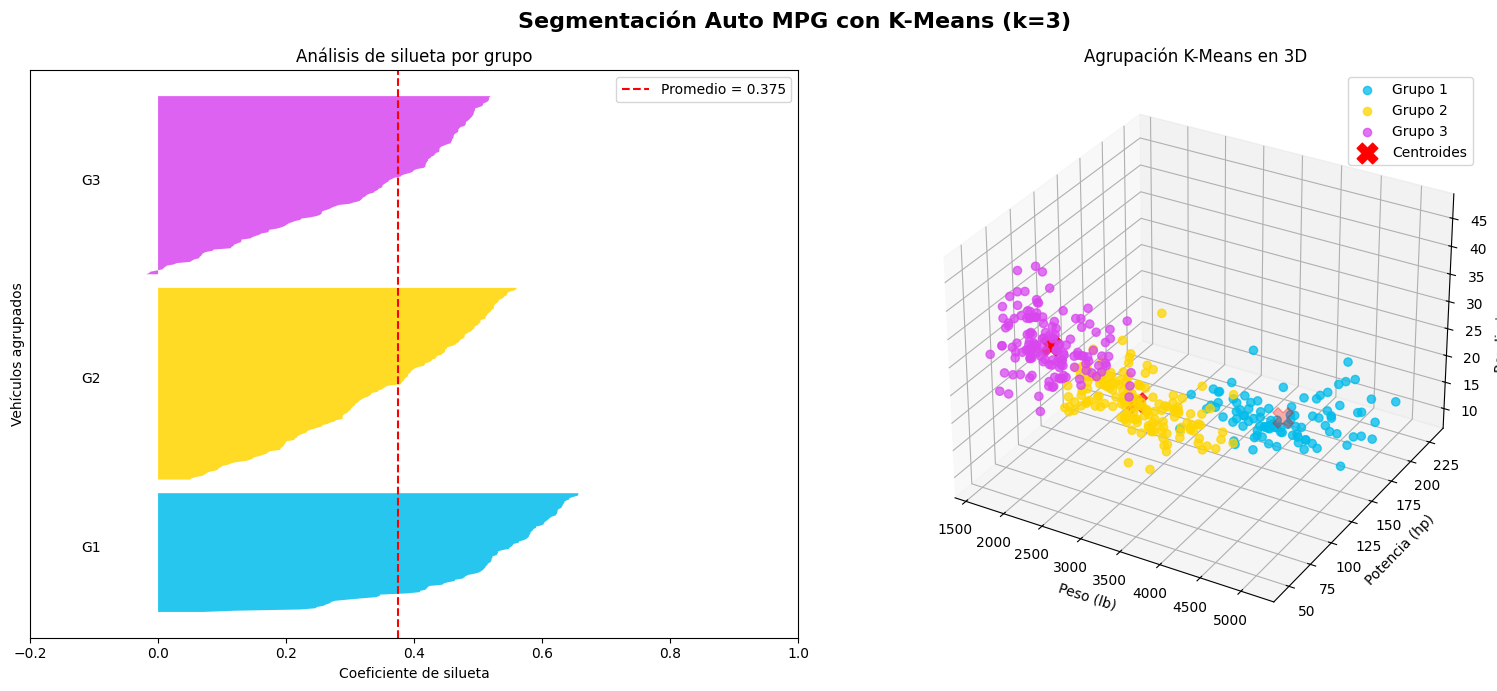

Silueta promedio: 0.375


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.metrics import silhouette_samples, silhouette_score

# Modelo K-Means ya entrenado en el laboratorio
etiquetas = km.labels_
k = km.n_clusters

# Calcular siluetas reales
silueta_media = silhouette_score(Z, etiquetas)
siluetas = silhouette_samples(Z, etiquetas)

fig = plt.figure(figsize=(16, 7))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")

colores = ["#00BCEB", "#FFD500", "#D946EF"]

# GRÁFICO 1: SILUETA
y_inferior = 10

for i in range(k):
    valores = np.sort(siluetas[etiquetas == i])
    cantidad = len(valores)
    y_superior = y_inferior + cantidad

    ax1.fill_betweenx(
        np.arange(y_inferior, y_superior),
        0, valores,
        facecolor=colores[i],
        alpha=0.85
    )

    ax1.text(-0.12, y_inferior + cantidad / 2, f"G{i+1}")
    y_inferior = y_superior + 10

ax1.axvline(
    silueta_media,
    color="red",
    linestyle="--",
    label=f"Promedio = {silueta_media:.3f}"
)

ax1.set_title("Análisis de silueta por grupo")
ax1.set_xlabel("Coeficiente de silueta")
ax1.set_ylabel("Vehículos agrupados")
ax1.set_xlim(-0.2, 1)
ax1.set_yticks([])
ax1.legend()

# GRÁFICO 2: AGRUPACIÓN EN 3D
# Se visualizan tres variables originales
for i in range(k):
    grupo = autos[etiquetas == i]

    ax2.scatter(
        grupo["peso"],
        grupo["potencia"],
        grupo["rendimiento_mpg"],
        color=colores[i],
        label=f"Grupo {i+1}",
        s=35,
        alpha=0.75
    )

# Centroides en unidades originales
centros = escalador.inverse_transform(
    km.cluster_centers_
)

ax2.scatter(
    centros[:, 0],
    centros[:, 1],
    centros[:, 3],
    color="red",
    marker="X",
    s=220,
    label="Centroides"
)

ax2.set_xlabel("Peso (lb)")
ax2.set_ylabel("Potencia (hp)")
ax2.set_zlabel("Rendimiento (mpg)")
ax2.set_title("Agrupación K-Means en 3D")
ax2.legend()

fig.suptitle(
    f"Segmentación Auto MPG con K-Means (k={k})",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(f"Silueta promedio: {silueta_media:.3f}")


**Pregunta 4.** ¿Dónde aparece el codo en la gráfica y qué pasa con la inercia al seguir aumentando k?

**Respuesta:** El codo aparece en k = 3: la inercia baja de 733.0 a 500.3 al pasar de 2 a 3, pero solo de 500.3 a 406.3 al pasar de 3 a 4. Después sigue bajando cada vez menos, hasta 246.9 con k = 8.

**Pregunta 5.** Compare las siluetas de k = 2, 3 y 4. ¿Qué k elige y por qué, aunque k = 2 tenga la mayor silueta?

**Respuesta:** Las siluetas son 0.500 con k = 2, 0.375 con k = 3 y 0.348 con k = 4. Elijo k = 3 porque es donde está el codo y da tres tipos de auto útiles para decidir la compra (livianos, intermedios y pesados). Con k = 2 la silueta es mayor, pero solo habría dos tipos.

### Ejercicio 4 — Perfiles y nombres de los segmentos

**Fase CRISP-DM.** Modelado (celda 7) y evaluación (celdas 8 y 9).

Con k = 3 se asigna el segmento a cada auto y se calcula el perfil: el promedio de cada variable por segmento, en unidades originales, que es lo que se puede leer en lenguaje de negocio. Los nombres se asignan según el peso promedio de cada segmento, de modo que no dependen del número que K-Means le dio al grupo.

**Se solicita.** Ejecute las celdas 7, 8 y 9.

**Celda 7 de 14**

In [9]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
autos["segmento"] = km.labels_

perfil = autos.groupby("segmento")[variables].mean().round(1)
perfil["autos"] = autos["segmento"].value_counts().sort_index()
perfil["% del total"] = (perfil["autos"] / len(autos) * 100).round(1)
display(perfil)

,peso,potencia,aceleracion,rendimiento_mpg,autos,% del total
segmento,,,,,,
0,4144.0,161.8,12.6,14.5,97,24.4
1,2974.3,98.0,16.2,21.3,156,39.2
2,2181.2,72.7,16.8,31.9,145,36.4


**Celda 8 de 14**

In [10]:
orden = perfil["peso"].sort_values().index
nombres = dict(zip(orden, ["Livianos y eficientes", "Intermedios", "Pesados y de alta potencia"]))
autos["nombre_segmento"] = autos["segmento"].map(nombres)

display(pd.crosstab(autos["nombre_segmento"], autos["origen"]))

origen,Europa,Japón,USA
nombre_segmento,,,
Intermedios,24,23,109
Livianos y eficientes,46,56,43
Pesados y de alta potencia,0,0,97


**Celda 9 de 14**

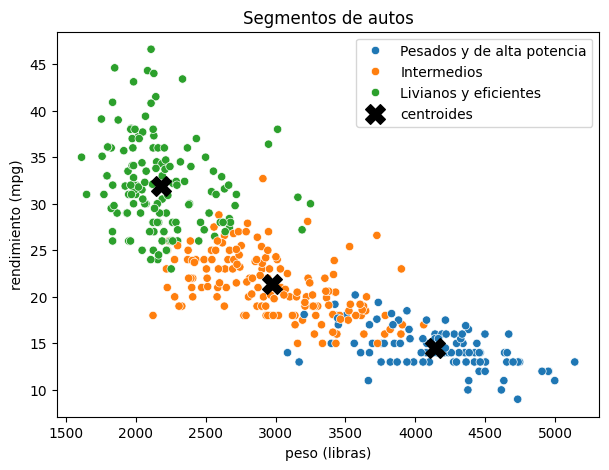

In [11]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=autos, x="peso", y="rendimiento_mpg", hue="nombre_segmento")
centros = escalador.inverse_transform(km.cluster_centers_)
plt.scatter(centros[:, 0], centros[:, 3], marker="X", s=200, color="black", label="centroides")
plt.xlabel("peso (libras)")
plt.ylabel("rendimiento (mpg)")
plt.title("Segmentos de autos")
plt.legend()
plt.show()

**Pregunta 6.** Describa el perfil de cada segmento con sus cifras: peso, potencia, rendimiento y tamaño.

**Respuesta:** Livianos y eficientes: peso 2181.2, potencia 72.7, rendimiento 31.9 mpg, 145 autos (36.4 %). Intermedios: peso 2974.3, potencia 98.0, rendimiento 21.3 mpg, 156 autos (39.2 %). Pesados y de alta potencia: peso 4144.0, potencia 161.8, rendimiento 14.5 mpg, 97 autos (24.4 %).

**Pregunta 7.** ¿Por qué se eligieron esos nombres? ¿Cómo se reparte el origen dentro de cada segmento y puede decirse que el origen causa el segmento?

**Respuesta:** Los nombres se asignan según el peso promedio de cada segmento, no según el número que le dio K-Means. Livianos: 46 de Europa, 56 de Japón y 43 de USA. Intermedios: 24 de Europa, 23 de Japón y 109 de USA. Pesados: 97 de USA y ninguno de Europa ni Japón. No se puede decir que el origen causa el segmento: los grupos se formaron con peso, potencia, aceleración y rendimiento, y el origen solo se observó después.

**Pregunta 8.** ¿Qué muestra el gráfico de dispersión con los centroides? ¿Los grupos están separados con nitidez?

**Respuesta:** Muestra que a más peso hay menos rendimiento, con los tres segmentos en tres zonas y un centroide (X) en cada una. Los grupos se distinguen pero los vecinos se tocan un poco, por eso la silueta es 0.375 y no cercana a 1.

### Ejercicio 5 — Registrar los segmentos en SQLite

**Fase CRISP-DM.** Despliegue.

El segmento se guarda como una columna nueva en autos_limpio con to_sql(). Así cualquier persona puede consultar los segmentos con SQL sin repetir el modelo.

**Se solicita.** Ejecute la celda 10.

**Celda 10 de 14**

In [12]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")

consulta = """SELECT nombre_segmento,
       COUNT(*) AS autos,
       ROUND(AVG(rendimiento_mpg), 1) AS mpg_promedio,
       ROUND(AVG(peso), 0) AS peso_promedio
FROM autos_limpio
GROUP BY nombre_segmento
ORDER BY peso_promedio;"""
display(pd.read_sql_query(consulta, conexion))

,nombre_segmento,autos,mpg_promedio,peso_promedio
0,Livianos y eficientes,145,31.9,2181.0
1,Intermedios,156,21.3,2974.0
2,Pesados y de alta potencia,97,14.5,4144.0


**Pregunta 9.** ¿Qué devuelve la consulta y cómo comprueba que la columna del segmento quedó registrada? ¿Por qué conviene guardarla en SQLite?

**Respuesta:** La consulta devuelve, por segmento, el número de autos, el mpg promedio y el peso promedio: Livianos 145, 31.9, 2181; Intermedios 156, 21.3, 2974; Pesados 97, 14.5, 4144. Se comprueba porque el GROUP BY por nombre_segmento funciona, lo que solo pasa si la columna existe en autos_limpio (y las cantidades suman 398). Conviene guardarla para consultar los segmentos con SQL sin volver a ejecutar el modelo.

## Actividad 3 — Usar los segmentos en la decisión

**Fase CRISP-DM.** Despliegue: uso del resultado en la decisión.

La gerencia tiene tres autos candidatos de compra (los de la semana 6, con su rendimiento estimado). Ejecute la celda 11, que asigna cada candidato a un segmento con km.predict(), y complete la tabla con los resultados.

**Celda 11 de 14**

In [13]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "aceleracion": [16, 15, 12],
    "rendimiento_mpg": [33.5, 26.5, 16.7]})

asignado = km.predict(escalador.transform(candidatos[variables]))
candidatos["segmento"] = pd.Series(asignado).map(nombres).values
display(candidatos)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


,candidato,peso,potencia,aceleracion,rendimiento_mpg,segmento
0,A,2200,80,16,33.5,Livianos y eficientes
1,B,3000,110,15,26.5,Intermedios
2,C,4200,160,12,16.7,Pesados y de alta potencia


| Candidato | Peso (lb) | Potencia | Rendimiento (mpg) | Segmento |
|---|---|---|---|---|
| A | 2 200 | 80 | 33,5 |  |
| B | 3 000 | 110 | 26,5 |  |
| C | 4 200 | 160 | 16,7 |  |

**A.** ¿A qué segmento pertenece cada candidato y qué tipo de uso de la flota sugiere cada segmento?

**Respuesta:** A es Livianos y eficientes: sugiere uso de ciudad y reparto liviano, con poco consumo. B es Intermedios: sugiere un uso mixto. C es Pesados y de alta potencia: sugiere trabajo exigente, con consumo alto.

**B.** Ubique en su fase de CRISP-DM tres pasos de este laboratorio: el escalado, la silueta y el registro en SQLite. Si la gerencia dijera que los tres segmentos no le sirven para decidir la compra, ¿a qué fase volvería y qué cambiaría?

**Respuesta:** El escalado es preparación de los datos, la silueta es evaluación y el registro en SQLite es despliegue. Si los segmentos no sirven, volvería a la comprensión del negocio para aclarar qué decisión necesita la gerencia, y luego cambiaría las variables o el número de grupos y repetiría el modelado y la evaluación.

## Reto de aplicación y retroalimentación

Indicaciones. Cada reto presenta el código ya escrito: ejecútelo, identifique qué hace cada instrucción e interprete el resultado con cifras. No se trata de cambiar el código sino de leerlo y explicarlo.

### Reto 1 — ¿Y si no se escala?

Dirección técnica pregunta si el escalado es de verdad necesario. Se ajusta K-Means con las variables originales y se compara.

**Celda 12 de 14**

In [14]:
km_sin = KMeans(n_clusters=3, n_init=10, random_state=42).fit(autos[variables])
print("Silueta sin escalar:", round(silhouette_score(autos[variables], km_sin.labels_), 3))
print("Silueta con escalado:", round(silhouette_score(Z, km.labels_), 3))
display(autos.assign(grupo_sin_escalar=km_sin.labels_)
        .groupby("grupo_sin_escalar")[variables].mean().round(1))

Silueta sin escalar: 0.592
Silueta con escalado: 0.375


,peso,potencia,aceleracion,rendimiento_mpg
grupo_sin_escalar,,,,
0,2217.7,77.3,16.4,29.8
1,3157.8,105.5,15.9,20.8
2,4242.4,157.7,13.5,14.6


**Pregunta de cierre.** ¿Qué pasa con la silueta y con los grupos al no escalar? ¿Por qué una silueta mayor no significa mejores segmentos?

**Respuesta:** Sin escalar la silueta sube a 0.592 (con escalado era 0.375). Los grupos quedan casi ordenados solo por peso: promedios de 2217.7, 3157.8 y 4242.4 libras, con un rendimiento de 29.8, 20.8 y 14.6 mpg. La silueta es mayor porque el peso, con números grandes, decide casi todo el agrupamiento y las demás variables dejan de influir. Una silueta mayor no significa mejores segmentos si no usa todas las variables.

### Reto 2 — ¿Tres o cuatro segmentos?

Marketing propone un grupo más. Se ajusta K-Means con k = 4 y se compara con k = 3.

**Celda 13 de 14**

In [15]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
print("Silueta con k = 3:", round(silhouette_score(Z, km.labels_), 3))
print("Silueta con k = 4:", round(silhouette_score(Z, km4.labels_), 3))

perfil4 = autos.assign(grupo4=km4.labels_).groupby("grupo4")[variables].mean().round(1)
perfil4["autos"] = np.bincount(km4.labels_)
display(perfil4)

Silueta con k = 3: 0.375
Silueta con k = 4: 0.348


,peso,potencia,aceleracion,rendimiento_mpg,autos
grupo4,,,,,
0,3157.7,98.4,17.0,20.1,109
1,2358.0,86.7,14.7,27.9,118
2,4147.1,162.1,12.6,14.5,96
3,2155.6,66.6,18.6,33.2,75


**Pregunta de cierre.** ¿Cómo cambian la silueta y los perfiles con k = 4? ¿Convendría pasar a cuatro segmentos?

**Respuesta:** Con k = 4 la silueta baja de 0.375 a 0.348. Los perfiles quedan en 109, 118, 96 y 75 autos, con rendimientos de 20.1, 27.9, 14.5 y 33.2 mpg, y los grupos intermedios se parecen entre sí. No convendría pasar a cuatro: la silueta es menor y con tres segmentos la historia ya es clara.

### Reto 3 — ¿Son estables los grupos?

El índice de Rand ajustado (ARI) mide el acuerdo entre dos agrupaciones: 1 es acuerdo perfecto y valores cercanos a 0 indican que no coinciden. Se compara el ajuste del laboratorio con otro hecho con otra semilla y una sola inicialización.

**Celda 14 de 14**

In [16]:
otra = KMeans(n_clusters=3, n_init=1, random_state=7).fit(Z)
print("Acuerdo entre los dos ajustes (ARI):", round(adjusted_rand_score(km.labels_, otra.labels_), 3))
print("Inercia del primero:", round(km.inertia_, 1), "| del segundo:", round(otra.inertia_, 1))

Acuerdo entre los dos ajustes (ARI): 1.0
Inercia del primero: 500.3 | del segundo: 500.3


**Pregunta de cierre.** ¿Qué indica el ARI y por qué se usa n_init = 10?

**Respuesta:** El ARI mide el acuerdo entre dos agrupaciones; aquí vale 1.0, es decir, los dos ajustes dieron los mismos grupos y son estables (con inercia 500.3 en ambos). Se usa n_init = 10 porque prueba diez inicializaciones y conserva la mejor, para no quedarse con un mal punto de partida.

## Conclusiones

Escriba tres conclusiones técnicas y de negocio de este laboratorio.

1. El escalado fue necesario: sin escalar la silueta sube a 0.592 pero el peso decide casi todo, y con escalado se usan las cuatro variables por igual.

2. K-Means con k = 3 (codo, silueta 0.375) separó la oferta en tres tipos: livianos y eficientes (145 autos, 31.9 mpg), intermedios (156 autos, 21.3 mpg) y pesados de alta potencia (97 autos, 14.5 mpg), y los grupos resultaron estables (ARI 1.0).

3. Los candidatos A, B y C caen en los tres segmentos, lo que ayuda a decidir la compra por tipo de uso. Los datos son históricos (1970 a 1982) y la silueta es moderada, así que el resultado es una guía y no una decisión final.